# LaStBeRu x DP2

This notebook processes DiaObjects and Objects independently. Each result has its own variable and pickle file.

## Preparation of dataset

In [26]:
from astropy.coordinates import SkyCoord
import astropy.units as u
from lsst.rsp import get_tap_service
import pandas as pd
import pickle
from tqdm import tqdm

tap_service = get_tap_service("tap")
TARGETS_CSV="lastberuXdp2_coords.csv"
BATCH_SIZE=100
targets=pd.read_csv(TARGETS_CSV)
targets.columns=targets.columns.astype(str).str.strip()
target_coords=SkyCoord(targets["coord_ra"].to_numpy()*u.deg,targets["coord_dec"].to_numpy()*u.deg)
targets.head()

,object_id,ra,dec,coord_ra,coord_dec
0,LaStBeRu_J014341.5+194553.4,25.92287,19.76483,25.922936,19.764723
1,LaStBeRu_J013732.6+210924.3,24.38567,21.15675,24.385600,21.156802
2,LaStBeRu_J014230.1+211832.9,25.62550,21.30912,25.625478,21.309121
3,LaStBeRu_J233356.1-142304.6,353.48358,-14.38460,353.483548,-14.384629
4,LaStBeRu_J232833.1-143453.8,352.13779,-14.58160,352.137848,-14.581657


## 1. DiaObjects

Result: dia_objects_by_target -> lastberu_dia_objects.pkl

In [ ]:
import os

DIA_OBJECTS_PICKLE = "lastberu_dia_objects.pkl"
if os.path.exists(DIA_OBJECTS_PICKLE):
    with open(DIA_OBJECTS_PICKLE, "rb") as file:
        dia_objects_by_target = pickle.load(file)
    print(f"Loaded existing results from {DIA_OBJECTS_PICKLE}")
else:
    DIA_OBJECT_TABLE="dp2.DiaObject"
    DIA_RADIUS_ARCSEC=20.0
    DIA_RADIUS_DEG=DIA_RADIUS_ARCSEC/3600.0
    DIA_OBJECTS_PICKLE="lastberu_dia_objects.pkl"
    dia_matches={i:[] for i in range(len(targets))}
    for start in tqdm(range(0,len(targets),BATCH_SIZE),desc="DiaObject TAP queries"):
        stop=min(start+BATCH_SIZE,len(targets))
        clauses=[f"CONTAINS(POINT('ICRS',ra,dec),CIRCLE('ICRS',{ra:.15g},{dec:.15g},{DIA_RADIUS_DEG:.15g}))=1" for ra,dec in zip(targets["coord_ra"].iloc[start:stop],targets["coord_dec"].iloc[start:stop])]
        query=f"SELECT diaObjectId,ra,dec FROM {DIA_OBJECT_TABLE} WHERE {' OR '.join(clauses)}"
        job=tap_service.submit_job(query); job.run(); job.wait(phases=["COMPLETED","ERROR"])
        if job.phase=="ERROR": job.raise_if_error()
        batch_dia_objects=job.fetch_result().to_table().to_pandas()
        if batch_dia_objects.empty: continue
        dia_coords=SkyCoord(batch_dia_objects["ra"].to_numpy()*u.deg,batch_dia_objects["dec"].to_numpy()*u.deg)
        idx_dia,idx_target,separations,_=target_coords[start:stop].search_around_sky(dia_coords,DIA_RADIUS_ARCSEC*u.arcsec)
        for i_target,i_dia,separation in zip(idx_target,idx_dia,separations):
            row=batch_dia_objects.iloc[int(i_dia)].to_dict(); row["sep_arcsec"]=separation.arcsec
            dia_matches[start+int(i_target)].append(row)
    dia_objects_by_target={target["object_id"]:pd.DataFrame(dia_matches[i],columns=["diaObjectId","ra","dec","sep_arcsec"]) for i,target in targets.iterrows()}
    with open(DIA_OBJECTS_PICKLE,"wb") as file: pickle.dump(dia_objects_by_target,file)
    print(f"Saved to {DIA_OBJECTS_PICKLE}")


DiaObject TAP queries:  17%|█▋        | 4/24 [02:12<09:33, 28.66s/it]

In [27]:
import os
if "dia_objects_by_target" not in globals():
    with open("lastberu_dia_objects.pkl", "rb") as file:
        dia_objects_by_target = pickle.load(file)

dia_match_counts = pd.Series(
    {target_id: len(matches) for target_id, matches in dia_objects_by_target.items()},
    name="n_dia_objects",
)
dia_match_counts.describe()


count    2287.000000
mean        6.535199
std        12.534937
min         0.000000
25%         1.000000
50%         3.000000
75%         7.000000
max       212.000000
Name: n_dia_objects, dtype: float64

## 2. Objects

Result: objects_by_target -> lastberu_objects.pkl. This section does not overwrite the DiaObject result.

In [25]:
import os

OBJECTS_PICKLE = "lastberu_objects.pkl"
if os.path.exists(OBJECTS_PICKLE):
    with open(OBJECTS_PICKLE, "rb") as file:
        objects_by_target = pickle.load(file)
    print(f"Loaded existing results from {OBJECTS_PICKLE}")
else:
    OBJECT_TABLE="dp2.Object"
    OBJECT_RADIUS_ARCSEC=40.0
    OBJECT_RADIUS_DEG=OBJECT_RADIUS_ARCSEC/3600.0
    OBJECTS_PICKLE="lastberu_objects.pkl"
    object_matches={i:[] for i in range(len(targets))}
    for start in tqdm(range(0,len(targets),BATCH_SIZE),desc="Object TAP queries"):
        stop=min(start+BATCH_SIZE,len(targets))
        clauses=[f"CONTAINS(POINT('ICRS',coord_ra,coord_dec),CIRCLE('ICRS',{ra:.15g},{dec:.15g},{OBJECT_RADIUS_DEG:.15g}))=1" for ra,dec in zip(targets["coord_ra"].iloc[start:stop],targets["coord_dec"].iloc[start:stop])]
        query=f"SELECT objectId,coord_ra,coord_dec FROM {OBJECT_TABLE} WHERE {' OR '.join(clauses)}"
        job=tap_service.submit_job(query); job.run(); job.wait(phases=["COMPLETED","ERROR"])
        if job.phase=="ERROR": job.raise_if_error()
        batch_objects=job.fetch_result().to_table().to_pandas()
        if batch_objects.empty: continue
        object_coords=SkyCoord(batch_objects["coord_ra"].to_numpy()*u.deg,batch_objects["coord_dec"].to_numpy()*u.deg)
        idx_object,idx_target,separations,_=target_coords[start:stop].search_around_sky(object_coords,OBJECT_RADIUS_ARCSEC*u.arcsec)
        for i_target,i_object,separation in zip(idx_target,idx_object,separations):
            row=batch_objects.iloc[int(i_object)].to_dict(); row["sep_arcsec"]=separation.arcsec
            object_matches[start+int(i_target)].append(row)
    objects_by_target={target["object_id"]:pd.DataFrame(object_matches[i],columns=["objectId","coord_ra","coord_dec","sep_arcsec"]) for i,target in targets.iterrows()}
    with open(OBJECTS_PICKLE,"wb") as file: pickle.dump(objects_by_target,file)
    print(f"Saved to {OBJECTS_PICKLE}")


Object TAP queries:   0%|          | 0/24 [00:02<?, ?it/s]


KeyboardInterrupt: 

In [28]:
import os
if "objects_by_target" not in globals():
    with open("lastberu_objects.pkl", "rb") as file:
        objects_by_target = pickle.load(file)

object_match_counts = pd.Series(
    {target_id: len(matches) for target_id, matches in objects_by_target.items()},
    name="n_objects",
)
object_match_counts.describe()


count    2287.000000
mean       20.452121
std         9.715293
min         1.000000
25%        13.000000
50%        20.000000
75%        27.000000
max        72.000000
Name: n_objects, dtype: float64

## Saved results

- lastberu_dia_objects.pkl: target -> DataFrame of DiaObject matches.
- lastberu_objects.pkl: target -> DataFrame of Object matches.

## Histogramas de coincidencias

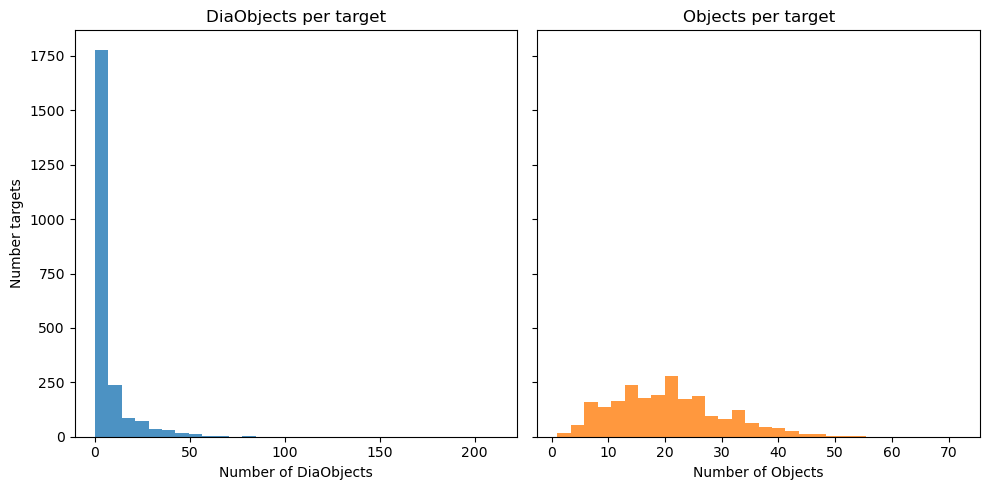

In [35]:
import matplotlib.pyplot as plt

# Calculate counts directly from the persisted/in-memory match dictionaries.
dia_match_counts = pd.Series(
    [len(matches) for matches in dia_objects_by_target.values()],
    name="n_dia_objects",
)
object_match_counts = pd.Series(
    [len(matches) for matches in objects_by_target.values()],
    name="n_objects",
)

fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True)
axes[0].hist(dia_match_counts.to_numpy(), bins=30, color="tab:blue", alpha=0.8)
axes[0].set_title("DiaObjects per target")
axes[0].set_xlabel("Number of DiaObjects")
axes[0].set_ylabel("Number targets")
axes[1].hist(object_match_counts.to_numpy(), bins=30, color="tab:orange", alpha=0.8)
axes[1].set_title("Objects per target")
axes[1].set_xlabel("Number of Objects")
plt.tight_layout()
plt.savefig("nerby_obj_distrib.png")


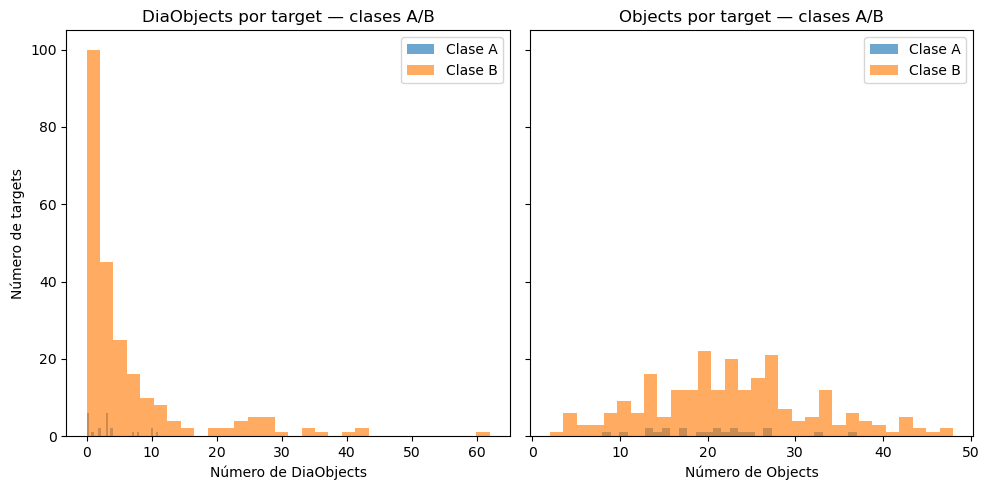

In [34]:
import matplotlib.pyplot as plt
import pandas as pd

lastberu = pd.read_csv("LaStBeRu_watchlist_LSST_grades.csv")
lastberu["vetting_grade"] = lastberu["extra_info"].astype(str).str[14]
grades = (
  lastberu[["object_id", "vetting_grade"]]
  .drop_duplicates("object_id")
  .set_index("object_id")["vetting_grade"]
)

dia_counts = {
  grade: [
      len(dia_objects_by_target[target_id])
      for target_id in dia_objects_by_target
      if grades.get(target_id) == grade
  ]
  for grade in ["A", "B"]
}
object_counts = {
  grade: [
      len(objects_by_target[target_id])
      for target_id in objects_by_target
      if grades.get(target_id) == grade
  ]
  for grade in ["A", "B"]
}
fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True)
colors = {"A": "tab:blue", "B": "tab:orange"}

for grade in ["A", "B"]:
  axes[0].hist(
      dia_counts[grade],
      bins=30,
      color=colors[grade],
      alpha=0.65,
      label=f"Clase {grade}",
  )

axes[0].set_title("DiaObjects por target — clases A/B")
axes[0].set_xlabel("Número de DiaObjects")
axes[0].set_ylabel("Número de targets")
axes[0].legend()

# Histograma de Objects
for grade in ["A", "B"]:
  axes[1].hist(object_counts[grade],bins=30, color=colors[grade],alpha=0.65, label=f"Clase {grade}",)

axes[1].set_title("Objects por target — clases A/B")
axes[1].set_xlabel("Número de Objects")
axes[1].legend()

plt.tight_layout()
plt.savefig("nerby_obj_distrib_gradeA.png")

## Cutouts de targets clasificados como A

Cada imagen contiene los `DiaObjects` y `Objects` del mismo target. Los `DiaObjects` se muestran en azul, los `Objects` en naranja y el círculo verde indica el radio de búsqueda de `Objects` (20 arcsec).

In [ ]:
import os
import numpy as np
from matplotlib.patches import Circle
from astropy.coordinates import SkyCoord
from astropy.visualization import ImageNormalize, AsinhStretch
from astropy.wcs.utils import proj_plane_pixel_scales
from lsst.daf.butler import Butler

with open("lastberu_dia_objects.pkl", "rb") as file:
    dia_objects_by_target = pickle.load(file)
with open("lastberu_objects.pkl", "rb") as file:
    objects_by_target = pickle.load(file)

lastberu = pd.read_csv("LaStBeRu_watchlist_LSST_grades.csv")
lastberu["vetting_grade"] = lastberu["extra_info"].astype(str).str[14]


CUTOUT_SIZE_ARCSEC = 80.0
OBJECT_SEARCH_RADIUS_ARCSEC = 20.0
CUTOUT_OUTPUT_DIR = "cutouts_A"
os.makedirs(CUTOUT_OUTPUT_DIR, exist_ok=True)
butler = Butler("dp2", collections="dp2")

def plot_cutouts_by_grade(lastberu, grade="A"):
    a_target_ids = set(lastberu.loc[lastberu["vetting_grade"].eq(grade), "object_id"])
    a_targets = targets[targets["object_id"].isin(a_target_ids)].copy()
    print(f"Targets clasificados como A: {len(a_targets)}")
    for _, target in a_targets.iterrows():
        target_id = target["object_id"]
        target_coord = SkyCoord(target["coord_ra"] * u.deg, target["coord_dec"] * u.deg)
        dia_matches = dia_objects_by_target[target_id]
        object_matches = objects_by_target[target_id]
        refs = list(butler.query_datasets(
            "deep_coadd",
            where="patch.region OVERLAPS POINT(:ra,:dec)",
            bind={"ra": target["coord_ra"], "dec": target["coord_dec"]},
        ))
        fig = plt.figure(figsize=(18, 10))
        for panel, band in enumerate("ugrizy", start=1):
            selected = None
            for ref in refs:
                if str(ref.dataId.get("band", "")) != band:
                    continue
                coadd = butler.get(ref)
                wcs = coadd.fits_wcs
                x, y = wcs.world_to_pixel(target_coord)
                image = np.asarray(coadd.image.array, dtype=float)
                height, width = image.shape
                if 0 <= x < width and 0 <= y < height:
                    selected = wcs, x, y, image, height, width
                    break
            ax = fig.add_subplot(2, 3, panel, projection=selected[0] if selected else None)
            if selected is None:
                ax.text(0.5, 0.5, f"No {band}", ha="center")
                ax.axis("off")
                continue
            wcs, x, y, image, height, width = selected
            pixel_scale = np.mean(proj_plane_pixel_scales(wcs)) * 3600.0
            half_size = int(CUTOUT_SIZE_ARCSEC / (2 * pixel_scale))
            x0, x1 = max(0, int(x) - half_size), min(width, int(x) + half_size)
            y0, y1 = max(0, int(y) - half_size), min(height, int(y) + half_size)
            cutout = image[y0:y1, x0:x1]
            finite = cutout[np.isfinite(cutout)]
            if len(finite) == 0:
                ax.axis("off")
                continue
            vmin, vmax = np.percentile(finite, [5, 99.5])
            ax.imshow(cutout, origin="lower", cmap="gray", extent=[x0, x1, y0, y1],
                      norm=ImageNormalize(vmin=vmin, vmax=vmax, stretch=AsinhStretch(0.08)))
            ax.plot(x, y, "ro", ms=8, mfc="none", mew=1.5, label="Target")
            radius_pixels = OBJECT_SEARCH_RADIUS_ARCSEC / pixel_scale
            ax.add_patch(Circle((x, y), radius_pixels, edgecolor="lime", facecolor="none", lw=1.8, label=f"Object search radius ({OBJECT_SEARCH_RADIUS_ARCSEC:.0f} arcsec)"))
            if not dia_matches.empty:
                dia_coords = SkyCoord(dia_matches["ra"].to_numpy() * u.deg, dia_matches["dec"].to_numpy() * u.deg)
                dia_x, dia_y = wcs.world_to_pixel(dia_coords)
                ax.plot(dia_x, dia_y, "o", color="tab:blue", ms=8, mfc="none", mew=1.5, label="DiaObjects")
            if not object_matches.empty:
                object_coords = SkyCoord(object_matches["coord_ra"].to_numpy() * u.deg, object_matches["coord_dec"].to_numpy() * u.deg)
                object_x, object_y = wcs.world_to_pixel(object_coords)
                ax.plot(object_x, object_y, "o", color="tab:orange", ms=7, mfc="none", mew=1.5, label="Objects")
            ax.set_xlim(x0, x1)
            ax.set_ylim(y0, y1)
            ax.set_title(f"{target_id} - {band} - DiaObjects: {len(dia_matches)} - Objects: {len(object_matches)}")
            ax.coords[0].set_axislabel("RA")
            ax.coords[1].set_axislabel("Dec")
        handles, labels = ax.get_legend_handles_labels()
        if handles:
            fig.legend(handles, labels, loc="upper right")
        plt.tight_layout()
        fig.savefig(os.path.join(CUTOUT_OUTPUT_DIR, f"{target_id}.png"), dpi=150, bbox_inches="tight")
        plt.close(fig)

plot_cutouts_by_grade(lastberu, grade="A")


In [ ]:
plot_cutouts_by_grade(lastberu, grade="B")

## Cutouts coloreados por magnitud

DiaObjects usa línea discontinua, Objects línea continua y el color representa la magnitud de cada fuente en la banda del panel.

In [23]:
import os, pickle
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable, get_cmap
from matplotlib.patches import Circle
from astropy.coordinates import SkyCoord
from astropy.visualization import ImageNormalize, AsinhStretch
from astropy.wcs.utils import proj_plane_pixel_scales
from lsst.daf.butler import Butler

OBJECT_SEARCH_RADIUS_ARCSEC = 40.0
DIA_SEARCH_RADIUS_ARCSEC = 40.0
CUTOUT_SIZE_ARCSEC = 80.0
MAGNITUDE_CUTOUT_DIR = "cutouts_A_magnitude"
os.makedirs(MAGNITUDE_CUTOUT_DIR, exist_ok=True)
DIA_MAG_CACHE = "lastberu_dia_magnitudes.pkl"
OBJECT_MAG_CACHE = "lastberu_object_magnitudes.pkl"

with open("lastberu_dia_objects_40arcsec.pkl", "rb") as f:
    dia_objects_by_target = pickle.load(f)
with open("lastberu_objects_20arcsec.pkl", "rb") as f:
    objects_by_target = pickle.load(f)

def flux_to_mag(flux):
    flux = float(flux)
    return 31.4 - 2.5 * np.log10(flux) if np.isfinite(flux) and flux > 0 else np.nan

def get_magnitudes(table, id_col, flux_cols, ids, cache):
    if os.path.exists(cache):
        with open(cache, "rb") as f: return pickle.load(f)
    result = {}
    ids = list(dict.fromkeys(int(x) for x in ids))
    for start in range(0, len(ids), 500):
        batch = ids[start:start + 500]
        query = f"SELECT {id_col}, {', '.join(flux_cols.values())} FROM {table} WHERE {id_col} IN ({', '.join(map(str, batch))})"
        job = tap_service.submit_job(query); job.run(); job.wait(phases=["COMPLETED", "ERROR"])
        if job.phase == "ERROR": job.raise_if_error()
        data = job.fetch_result().to_table().to_pandas()
        for _, row in data.iterrows():
            result[int(row[id_col])] = {band: flux_to_mag(row[col]) for band, col in flux_cols.items()}
    with open(cache, "wb") as f: pickle.dump(result, f)
    return result

dia_flux_cols = {b: f"{b}PSFluxMean" for b in "ugrizy"}
object_flux_cols = {b: f"{b}_cModelFlux" for b in "ugrizy"}
dia_ids = [x for df in dia_objects_by_target.values() for x in df["diaObjectId"].dropna()]
object_id_column = "objectId" if any("objectId" in df.columns for df in objects_by_target.values()) else "ObjectId"
object_ids = [x for df in objects_by_target.values() for x in df[object_id_column].dropna()]
dia_magnitudes = get_magnitudes("dp2.DiaObject", "diaObjectId", dia_flux_cols, dia_ids, DIA_MAG_CACHE)
object_magnitudes = get_magnitudes("dp2.Object", object_id_column, object_flux_cols, object_ids, OBJECT_MAG_CACHE)

def plot_A_cutouts_by_magnitude():
    catalog = pd.read_csv("LaStBeRu_watchlist_LSST_grades.csv")
    catalog["vetting_grade"] = catalog["extra_info"].astype(str).str[14]
    selected = targets[targets["object_id"].isin(set(catalog.loc[catalog["vetting_grade"].isin(["A", "B"]), "object_id"]))]
    butler = Butler("dp2", collections="dp2")
    cmap, norm = get_cmap("viridis"), Normalize(18, 28, clip=True)
    for _, target in selected.iterrows():
        target_id = target["object_id"]
        coord = SkyCoord(target["coord_ra"] * u.deg, target["coord_dec"] * u.deg)
        dia = dia_objects_by_target.get(target_id, pd.DataFrame())
        obj = objects_by_target.get(target_id, pd.DataFrame())
        refs = list(butler.query_datasets("deep_coadd", where="patch.region OVERLAPS POINT(:ra,:dec)", bind={"ra": target["coord_ra"], "dec": target["coord_dec"]}))
        fig = plt.figure(figsize=(19, 11))
        for panel, band in enumerate("ugrizy", 1):
            selected_coadd = None
            for ref in refs:
                if str(ref.dataId.get("band", "")) != band: continue
                coadd = butler.get(ref); wcs = coadd.fits_wcs; x, y = wcs.world_to_pixel(coord); image = np.asarray(coadd.image.array, float); height, width = image.shape
                if 0 <= x < width and 0 <= y < height: selected_coadd = wcs, x, y, image, height, width; break
            ax = fig.add_subplot(2, 3, panel, projection=selected_coadd[0] if selected_coadd else None)
            if selected_coadd is None: ax.text(.5, .5, f"No {band}", ha="center"); ax.axis("off"); continue
            wcs, x, y, image, height, width = selected_coadd; scale = np.mean(proj_plane_pixel_scales(wcs)) * 3600; half = int(CUTOUT_SIZE_ARCSEC / (2 * scale)); x0, x1 = max(0, int(x)-half), min(width, int(x)+half); y0, y1 = max(0, int(y)-half), min(height, int(y)+half); cut = image[y0:y1, x0:x1]; finite = cut[np.isfinite(cut)]
            if len(finite) == 0: ax.axis("off"); continue
            lo, hi = np.percentile(finite, [5, 99.5]); ax.imshow(cut, origin="lower", cmap="gray", extent=[x0,x1,y0,y1], norm=ImageNormalize(vmin=lo, vmax=hi, stretch=AsinhStretch(.08))); ax.plot(x, y, "ro", mfc="none")
            for frame, id_col, ra_col, dec_col, mags, radius, linestyle in [(dia, "diaObjectId", "ra", "dec", dia_magnitudes, DIA_SEARCH_RADIUS_ARCSEC, "--"), (obj, object_id_column, "coord_ra", "coord_dec", object_magnitudes, OBJECT_SEARCH_RADIUS_ARCSEC, "-")]:
                for _, row in frame.iterrows():
                    source_id = int(row[id_col]); sx, sy = wcs.world_to_pixel(SkyCoord(row[ra_col]*u.deg, row[dec_col]*u.deg)); mag = mags.get(source_id, {}).get(band, np.nan); color = "gray" if not np.isfinite(mag) else cmap(norm(mag)); ax.add_patch(Circle((sx, sy), radius/scale, edgecolor=color, facecolor="none", linestyle=linestyle, linewidth=1.4))
            ax.set_xlim(x0,x1); ax.set_ylim(y0,y1); ax.set_title(f"{target_id} - {band} - {catalog.loc[catalog.object_id.eq(target_id), 'vetting_grade'].iloc[0]}")
        fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), ax=fig.axes, label="AB magnitude"); fig.suptitle(f"{target_id}: DiaObjects (--), Objects (-)"); plt.tight_layout(); fig.savefig(os.path.join(MAGNITUDE_CUTOUT_DIR, f"{target_id}.png"), dpi=150, bbox_inches="tight"); plt.show(); plt.close(fig)

plot_A_cutouts_by_magnitude()


DALQueryError: Query Error: IllegalArgumentException:validateColumnNonAlias: Column: [uPSFluxMean] does not exist.